In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [3]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) 

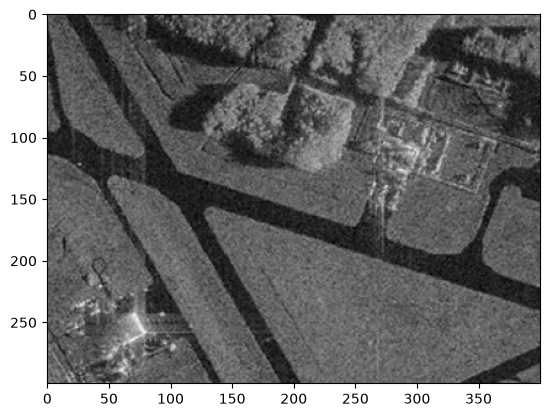

In [4]:
plt.imshow(image_gray, cmap="gray")

In [5]:
# 1. Подберите парамтеры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.

In [6]:
import math
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

In [7]:
def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        print(count)
        mask += local_mask
        
    return mask*255
    

In [28]:
seed_point = (250,250)
mask = region_growing(image_gray,seed_point,homo_average, 6, 25)

141
386
619
866
1106
1343
1591
1377
1362
1315
1251
1150
1070
1011
991
967
969
958
1036
1060
1144
1197
1305
1177
976
1008
975
982
1149
1314
1528
1626
1368
985
1124
1201
1486
1154
1144
1230
1154
1305
1427
1279
1242
1250
1216
1396
1529
1192
974
1104
1052
1085
1167
1263
1380
1439
1408
1274
1268
1926
1142
1133
1140
1006
341
317
224
159
99
80
58
10
0


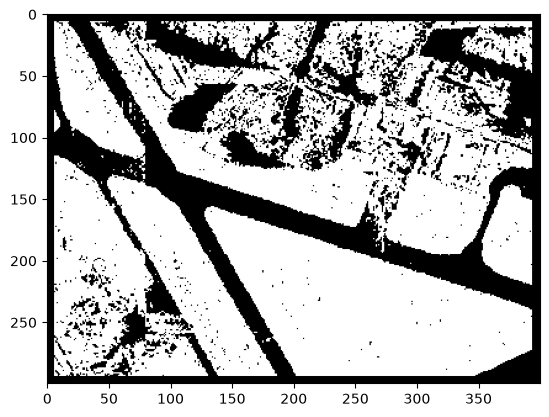

In [29]:
plt.imshow(mask, cmap="gray")

In [30]:
# 2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.

56
196
314
397
434
528
516
592
726
844
1043
951
1034
1275
1293
1601
1574
1952
2151
1623
1584
1543
1902
2357
2404
2598
2404
2612
2443
2819
2838
2840
3086
3176
3227
3546
3819
3803
3895
4075
4243
4459
4427
4485
5175
4489
3838
3422
5380
1549
952
746
3397
630
377
222
177
144
44
6
0


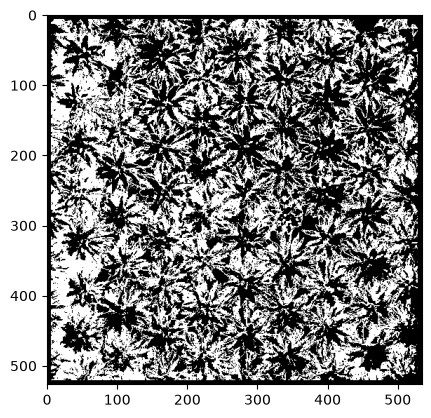

In [40]:
def homo_median(img, mask, point, T):
    median = np.median(img[mask > 0])
    return abs(median - img[point]) <= T

mask_median = region_growing(image_gray, seed_point, homo_median, 6, 25)
plt.imshow(mask_median, cmap="gray")

In [48]:
from skimage.transform import resize
import numpy as np
from skimage.metrics import structural_similarity, mean_squared_error

mask = resize(mask, image_gray.shape, order=0,
              preserve_range=True, anti_aliasing=False).astype(np.uint8)

mse_average = mean_squared_error(image_gray, mask)
mse_median  = mean_squared_error(image_gray, mask_median)
ssim_average, _ = structural_similarity(image_gray, mask,        data_range=255, full=True)
ssim_median,  _ = structural_similarity(image_gray, mask_median, data_range=255, full=True)

print(mse_average, ssim_average)
print(mse_median, ssim_median)

16625.98220220256 0.04834205746359942
22511.61952508468 -0.05581021924693887


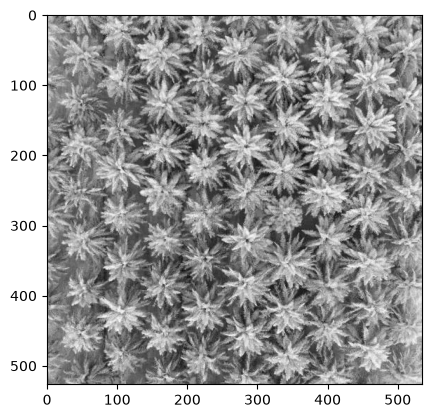

In [50]:
# 3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.

image = cv2.imread('palm_1.JPG')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")

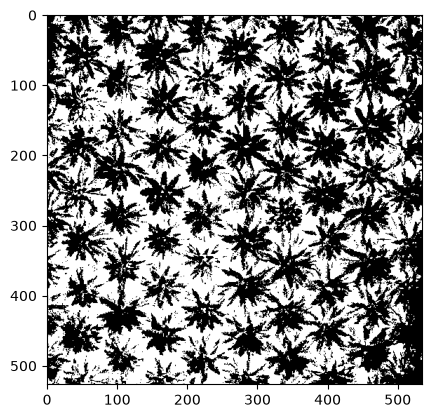

In [51]:
ret, thresh = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")

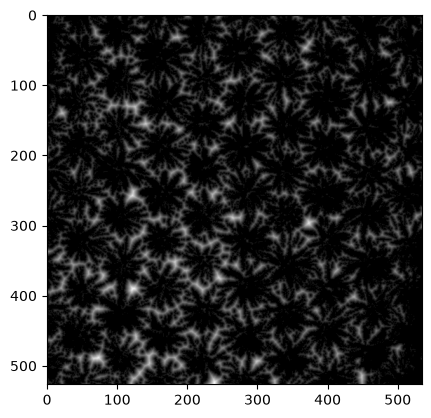

In [52]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")

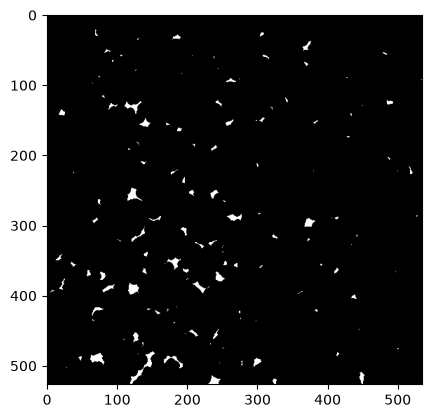

In [53]:
ret, sure_fg = cv2.threshold(dist, 0.5 * dist.max(), 255, cv2.THRESH_BINARY)
plt.imshow(sure_fg, cmap="gray")

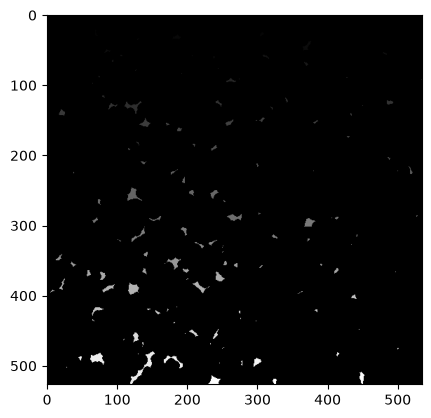

In [54]:
sure_fg = sure_fg.astype(np.uint8)
ret, markers = cv2.connectedComponents(sure_fg)
plt.imshow(markers, cmap="gray")

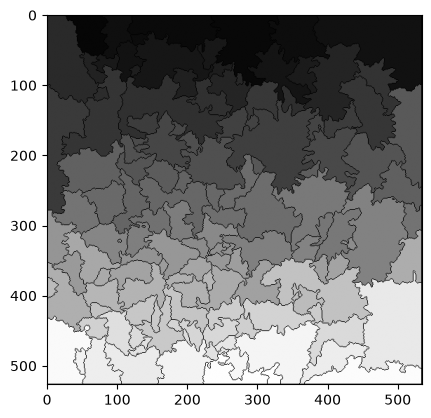

In [55]:
markers = cv2.watershed(image, markers)
plt.imshow(markers, cmap="gray")

In [56]:
count = len(np.unique(markers)) - 1
print(f"Количество деревьев: {count}")

Количество деревьев: 145
